<a href="https://colab.research.google.com/github/clementmonie12/ds-507/blob/main/hw7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
# connect to Google Drive
from google.colab import drive
drive.mount('/content/drive')

# navigate to your folder
import os
os.chdir('/content/drive/MyDrive/DS507/Week10')

print("Current directory:", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Current directory: /content/drive/MyDrive/DS507/Week10


# Question 1 (18 pts)
We will look into the NYC flights dataset using Pandas!

## Question 1.1 (2 pts)
Load the dataset from flights.csv file given with this file into a dataframe variable named `df`

In [18]:
import pandas as pd
df = pd.read_csv('flights.csv')
# YOUR CODE HERE
df.head()
# raise NotImplementedError()

,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400.0,5.0,15.0,1.357034e+09
1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416.0,5.0,29.0,1.357034e+09
2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089.0,5.0,40.0,1.357034e+09
3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,B6,725,N804JB,JFK,BQN,183.0,1576.0,5.0,45.0,1.357034e+09
4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,DL,461,N668DN,LGA,ATL,116.0,762.0,6.0,0.0,1.357038e+09


In [19]:
assert df is not None
assert isinstance(df, pd.core.frame.DataFrame)

## Question 1.2 (2 pts)
Get the total count of flights for each month and display the top three months with the highest count.

In [20]:
monthly_count = ...
# YOUR CODE HERE
monthly_count = df.groupby('month').size().sort_values(ascending=False).head(3)

monthly_count
# raise NotImplementedError()

,0
month,
7,29425
8,29327
10,28889


In [21]:
assert all(monthly_count == pd.Series([29425, 29327, 28889], index = [7, 8, 10]))

## Question 1.3 (2 pts)
First get a new dataframe with the three columns of interest 'carrier', 'month' and 'dep_delay'. Then compute the average dep_delay for each carrier and for each month. Rank the departure delays/month and filter the 1st rank carrier for each month (carrier with the lowest dep_delay for the month will get the 1st rank). Show the results in ascending order of the month

Hint: Some of the functions that can help are rank(), unstack(), stack().

In [22]:
avg_delay = ...
# YOUR CODE HERE
delay_by_carrier_month = (df[['carrier', 'month', 'dep_delay']]
    .groupby(['month', 'carrier'], as_index=False)['dep_delay'].mean())

delay_by_carrier_month['rank'] = delay_by_carrier_month.groupby('month')['dep_delay'].rank(method='min')
avg_delay = delay_by_carrier_month.loc[delay_by_carrier_month['rank'] == 1].sort_values('month').reset_index(drop=True)

avg_delay

# raise NotImplementedError()

,month,carrier,dep_delay,rank
0,1,VX,1.063492,1.0
1,2,AS,0.722222,1.0
2,3,HA,1.161290,1.0
3,4,HA,-2.100000,1.0
4,5,HA,-1.451613,1.0
5,6,HA,1.466667,1.0
6,7,HA,-1.709677,1.0
7,8,HA,1.677419,1.0
8,9,HA,-5.440000,1.0
9,10,HA,-5.095238,1.0


In [23]:
# Hidden test here

## Question 1.4 (2 pts)
Find the 5 top destinations in this dataset (most number of flights to). Filter only those flights to these top 5 destinations and then show the distribution of carriers on this filtered data.

In [24]:
top_dest = ...
top_carrier_count = ...
# YOUR CODE HERE
top_dest = df['dest'].value_counts().head(5).index.to_numpy()
top_carrier_count = df.loc[df['dest'].isin(top_dest), 'carrier'].value_counts()

top_carrier_count
# raise NotImplementedError()

,count
carrier,
UA,19469
DL,17707
B6,13448
AA,11826
MQ,4598
US,4283
VX,2580
FL,2337
9E,2029


In [25]:
import numpy as np
assert np.all(top_dest == np.array(['ORD', 'ATL', 'LAX', 'BOS', 'MCO']))

## Question 1.5 (2 pts)
Get the total count of cancelled flights in this dataset. We'll say that a cancelled flight has dep_time missing.

In [26]:
cancelled_flight_count = ...
# YOUR CODE HERE
cancelled_flight_count = df['dep_time'].isna().sum()

cancelled_flight_count
# raise NotImplementedError()

np.int64(8255)

In [27]:
assert cancelled_flight_count == 8255

## Question 1.6 (2 pts)
Count all the destinations that have a letter 'K' anywhere in the name code.

In [28]:
dest_with_k = df['dest'].str.contains('K', na=False).sum()

dest_with_k

# YOUR CODE HERE
# raise NotImplementedError()

np.int64(4589)

In [29]:
assert dest_with_k == 4589

## Question 1.7 (2 pts)
Create a new column called speed that computes the speed as distance/air_time

In [31]:
# YOUR CODE HERE
df['speed'] = df['distance'] / df['air_time']
# raise NotImplementedError()

In [32]:
assert type(df['speed']) == pd.Series
assert abs(df['speed'][0] - 6.1674) < 1

## Question 1.8 (4 pts)
Segment the dep_time 24 hours into
* night from 12 midnight to 5 am
* morning from 5:01 am to 12 noon
* afternoon from 12.01 noon to 5 pm
* evening from 5.01 pm to 12 am

And then run a query to find the total flights in each segment and save that value in the given variable.


In [35]:
minutes = (df['dep_time'] // 100) * 60 + (df['dep_time'] % 100)
parts_of_day = pd.cut(minutes, bins=[-1, 300, 720, 1020, 1440],
                      labels=['night', 'morning', 'afternoon', 'evening'])
parts_of_day_count = parts_of_day.value_counts().reindex(['night', 'morning', 'afternoon', 'evening'])

parts_of_day_count
# raise NotImplementedError()

,count
dep_time,
night,1487
morning,129939
afternoon,98733
evening,98362


In [36]:
assert parts_of_day_count['morning'] == 129939
assert parts_of_day_count['evening'] == 98362

# Question 2 (9 pts)
In this problem, we will do some exploratory data analytics (EDA) by using some of the visualization libraries in Python.

In [39]:
import numpy as np
import pandas as pd
import seaborn as sns
flights = pd.read_csv("flights.csv") #.gz
airports = pd.read_csv("airports.csv")
flights.describe()

,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,flight,air_time,distance,hour,minute,time_hour
count,336776.0,336776.000000,336776.000000,328521.000000,336776.000000,328521.000000,328063.000000,336776.000000,327346.000000,336776.000000,327346.000000,336776.000000,336776.000000,336776.000000,3.367760e+05
mean,2013.0,6.548510,15.710787,1349.109947,1344.254840,12.639070,1502.054999,1536.380220,6.895377,1971.923620,150.686460,1039.912604,13.180247,26.230100,1.372843e+09
std,0.0,3.414457,8.768607,488.281791,467.335756,40.210061,533.264132,497.457142,44.633292,1632.471938,93.688305,733.233033,4.661316,19.300846,9.009993e+06
min,2013.0,1.000000,1.000000,1.000000,106.000000,-43.000000,1.000000,1.000000,-86.000000,1.000000,20.000000,17.000000,1.000000,0.000000,1.357034e+09
25%,2013.0,4.000000,8.000000,907.000000,906.000000,-5.000000,1104.000000,1124.000000,-17.000000,553.000000,82.000000,502.000000,9.000000,8.000000,1.365095e+09
50%,2013.0,7.000000,16.000000,1401.000000,1359.000000,-2.000000,1535.000000,1556.000000,-5.000000,1496.000000,129.000000,872.000000,13.000000,29.000000,1.372860e+09
75%,2013.0,10.000000,23.000000,1744.000000,1729.000000,11.000000,1940.000000,1945.000000,14.000000,3465.000000,192.000000,1389.000000,17.000000,44.000000,1.380625e+09
max,2013.0,12.000000,31.000000,2400.000000,2359.000000,1301.000000,2400.000000,2359.000000,1272.000000,8500.000000,695.000000,4983.000000,23.000000,59.000000,1.388549e+09


## Question 2.1 (3 pts)

Line charts are ideal to show a trend line. Draw a line chart to show monthly frequency count of flights as a trend line for the year 2013. Be sure to choose the correct data to display on the x-axis and y-axis.

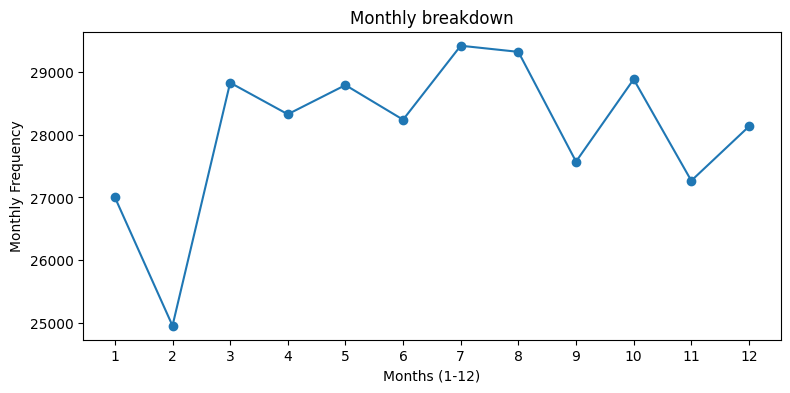

In [52]:
fig1 = None
# YOUR CODE HERE
monthly_frequency = flights.groupby('month').size()

fig1 = monthly_frequency.plot(
    kind = 'line',
    title = 'Monthly breakdown',
    xlabel = 'Months (1-12)',
    ylabel = 'Monthly Frequency',
    xticks = range(1, 13),
    marker = 'o',
    figsize = (9, 4)
)
# raise NotImplementedError()

In [44]:
assert fig1.get_title() == 'Monthly breakdown'
assert fig1.get_xlabel() == 'Months (1-12)'
assert fig1.get_ylabel() == 'Monthly Frequency'
assert dict(fig1.lines[0].get_xydata())[6] == 28243

## Question 2.2 (3 pts)
Show the top 5 airports that people flew into using a bar chart.

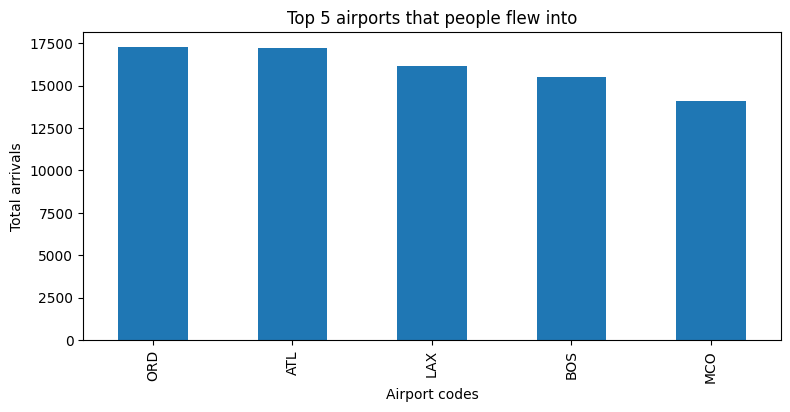

In [51]:
fig2 = None
# YOUR CODE HERE
top_5 = flights['dest'].value_counts().head(5)

fig_2 = top_5.plot(
    kind = 'bar',
    title = 'Top 5 airports that people flew into',
    xlabel = 'Airport codes',
    ylabel = 'Total arrivals',
    figsize = (9, 4)
)
# raise NotImplementedError()

In [46]:
x_axis = fig_2.get_xaxis()
text1 = x_axis.get_ticklabels()[0]
assert text1.get_text() == 'ORD'
assert fig_2.get_title() == 'Top 5 airports that people flew into'
assert fig_2.get_xlabel() == 'Airport codes'
assert fig_2.get_ylabel() == 'Total arrivals'

## Question 2.3 (3 pts)

Segment the flights based on time-slots with the following criteria
* flights that depart from 00-5:59am as 'red-eye' flights
* flights that depart from 6am - 11:59am as 'morning'
* flights that depart from 12noon - 3:59pm as 'afternoon'
* flights that depart from 4pm - 11:59pm as 'evening'

And using seaborn create a plot as shown below. PS: Feel free to choose your color palette.

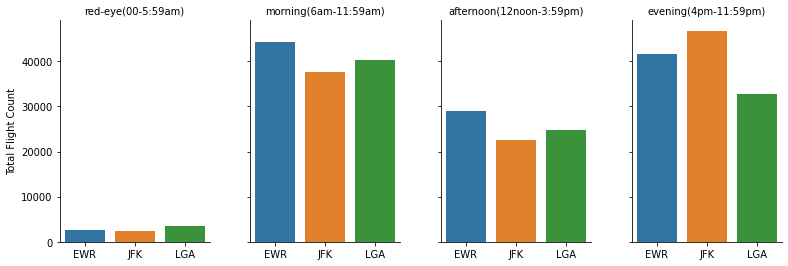

/tmp/ipykernel_389/2555479983.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  fig_3 = sns.catplot(


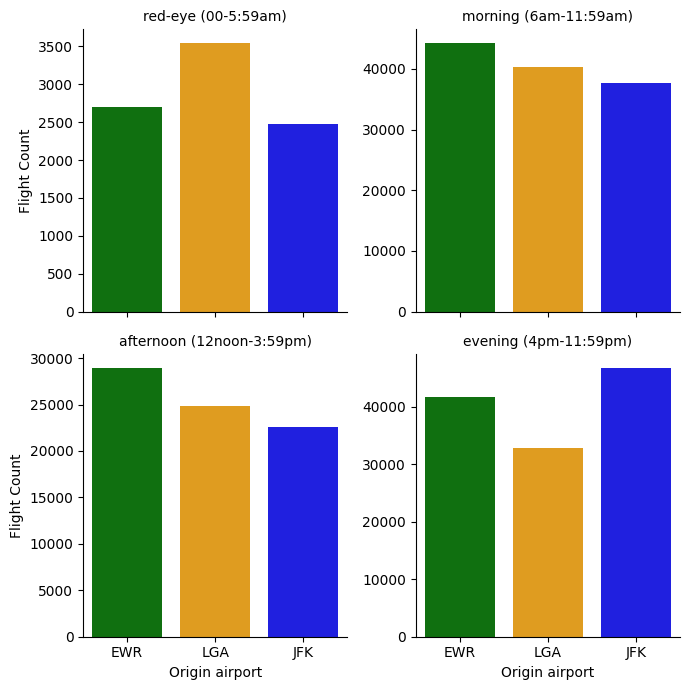

In [50]:
fig_3 = None
# YOUR CODE HERE
flights_segmented = flights.dropna(subset=['dep_time']).copy()

hour = (flights_segmented['dep_time'] // 100).astype(int)

flights_segmented['time_slot'] = pd.cut(
    hour,
    bins=[-1, 5, 11, 15, 23],
    labels=[
        'red-eye (00-5:59am)',
        'morning (6am-11:59am)',
        'afternoon (12noon-3:59pm)',
        'evening (4pm-11:59pm)'
    ]
)

fig_3 = sns.catplot(
    data=flights_segmented,
    x = 'origin',
    col = 'time_slot',
    col_wrap = 2,
    kind = 'count',
    sharey = False,
    height = 3.5,
    palette = {
        'JFK': 'blue',
        'LGA': 'orange',
        'EWR': 'green'
    }
)

fig_3.set_titles('{col_name}')
fig_3.set_axis_labels('Origin airport', 'Flight Count')
# raise NotImplementedError()

In [48]:
assert fig_3.figure.get_axes()[0].get_title() == 'red-eye(00-5:59am)'
assert fig_3.figure.get_axes()[0].get_ylabel() == 'Flight Count'
assert fig_3.figure.get_axes()[1].get_title() == 'morning(6am-11:59am)'